# Forecasting NO₂ and PM2.5 1–3 hours ahead

**STAT 473 — Statistical Consulting**

### What this notebook does

It answers one question, stated precisely:

> At hour **t**, for sensor **s**, using **only information available at t**,
> predict NO₂ and PM2.5 at **t+1**, **t+2** and **t+3**.

Every choice below gets checked against that sentence. If a piece of information
would not be on hand at hour *t* in real life, it cannot be an input — no matter
how much it improves the score.

### How to read this notebook

Each code cell has a markdown cell above it saying **what** it does, **why** we do
it that way, and **what to look for** in the output. Run top to bottom. Sections 1–7
take a few minutes total; nothing here needs a GPU or a long wait.

### What you need installed

`pandas`, `numpy`, `pyarrow`, `matplotlib`, `scipy` — all already in your `.venv`.
Section 11 is optional and needs `scikit-learn`, which you do **not** have yet.
Everything before it runs as-is.

---
## 1. Load the data

**What this does.** Reads `master_model.parquet` — the table built by `build_final.py`.
One row = one sensor, one hour.

**Why this file and not `master_hourly.parquet`.** `master_model` is the one with the
*targets* in it (`no2_t1`, `no2_t2`, …), the train/val/test split, the broken columns
removed, and the wind repaired. `master_hourly` is the raw input it was built from.

**What to look for.** 2,512,408 rows, 59 columns, 269 sensors. If you see 274 sensors
or a `traffic_speed` column, you are reading the old file.

In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 60)

DATA = "data/master_hourly/master_model.parquet"
DICT = "data/master_hourly/master_model_dictionary.csv"

m = pd.read_parquet(DATA)

print(f"rows     : {len(m):,}")
print(f"columns  : {m.shape[1]}")
print(f"sensors  : {m.sensor_id.nunique()}")
print(f"period   : {m.ts_local.min()}  ->  {m.ts_local.max()}")
print()
print(m.split.value_counts().sort_index().to_string())

rows     : 2,512,408
columns  : 59
sensors  : 269
period   : 2025-08-31 19:00:00-05:00  ->  2026-09-26 18:00:00-05:00

split
train    1557120
val       392352
test      562936


---
## 2. Let the dictionary decide what is legal

**What this does.** Reads the data dictionary and builds the feature list *from it*,
rather than typing column names by hand.

**Why this matters more than it looks.** The single most common way a forecasting
project produces fake results is **leakage** — letting the model see something it
would not know at prediction time. The classic version here would be using
`no2_t1` (the answer) or a future weather reading as an input.

By deriving the feature list from the `use_as_forecast_input` column, the rule lives
in one place that you and your teammates can both read, instead of in someone's memory.

**The subtle one.** `no2_city` is the average across all 269 sensors **for hour t**.
That is legal — in real-time operation you really would see every sensor's current
reading. What would *not* be legal is the citywide average at t+1. The dictionary
says `yes at t / NEVER at t+h` for exactly this reason.

**What to look for.** `no2_t1`, `pm25_aqi` and `split` should all be excluded.

In [36]:
dd = pd.read_csv(DICT)

print(dd.groupby("role").size().to_string())
print()
print("columns NOT allowed as model inputs:")
print(dd.loc[dd.use_as_forecast_input.str.startswith("NO") |
             dd.use_as_forecast_input.eq("no"),
             ["column", "role", "use_as_forecast_input"]].to_string(index=False))

role
TARGET          9
bookkeeping     1
feature        39
identifier      6
quality         2
reporting       2

columns NOT allowed as model inputs:
     column        role                   use_as_forecast_input
  sensor_id  identifier                                      no
sensor_name  identifier                                      no
     ts_utc  identifier                                      no
   ts_local  identifier                                      no
        lat  identifier                                      no
        lon  identifier                                      no
    no2_aqi   reporting NO - model concentration, convert after
   pm25_aqi   reporting NO - model concentration, convert after
     no2_t1      TARGET                   NO - it is the answer
     no2_t2      TARGET                   NO - it is the answer
     no2_t3      TARGET                   NO - it is the answer
    pm25_t1      TARGET                   NO - it is the answer
    pm25_t2      

### Grouping the legal columns into blocks

**What this does.** Sorts the allowed features into five groups.

**Why blocks and not individual columns.** In Section 7 we add one *block* at a time
and watch the error. That tells us "does knowing the weather help at all?" — a question
with a real answer. Testing 40 columns individually would just produce 40 p-values,
and with 1.5 million rows every one of them would be significant whether it mattered
or not. (Your n is also much smaller than it looks: wind has only 54 distinct values
across the whole table, because it is one O'Hare reading broadcast to every sensor.)

**⚠️ Circular variables — the trap this notebook originally fell into.**

Some numbers wrap around. Wind direction 359° and 1° are almost the same wind, but as
numbers they are 358 apart. **Hour 23 and hour 0 are one hour apart, but 23 apart as
numbers.** Feed either in raw and the model is told that midnight is the opposite of
11pm, which is nonsense.

`wdir` is handled by leaving it out and using `wind_u` / `wind_v` — the same information
split into east-west and north-south components, which really are linear.

`hour` and `dow` get the same treatment below, with sin and cos. The first version of
this notebook used them raw, concluded that time of day "adds nothing", and was wrong:
fixing the encoding turns the time block from the *worst* addition into the **best** one.
A conclusion that depends on how you encoded a variable is not a conclusion about the
world — it is a conclusion about your code.

In [37]:
LAGS = [1, 2, 3, 6, 12, 24]

# Put the circular variables back on a circle before using them.
for col, period in [("hour", 24), ("dow", 7)]:
    m[f"{col}_sin"] = np.sin(2*np.pi*m[col]/period).astype("float32")
    m[f"{col}_cos"] = np.cos(2*np.pi*m[col]/period).astype("float32")

def blocks_for(poll):
    '''Feature blocks for one pollutant. poll is 'no2' or 'log_pm25'.'''
    return {
        "lags":    [poll] + [f"{poll}_lag{k}" for k in LAGS],
        "time":    ["hour_sin", "hour_cos", "dow_sin", "dow_cos", "is_holiday"],
        "weather": ["temp", "rhum", "wspd_ms", "wind_u", "wind_v", "is_calm"],
        "city":    [f"{poll}_city"],
        "geo":     ["canopy_pct", "impervious_pct", "dist_downtown_m",
                    "road_len_expwy_500", "industrial_m2_500"],
    }

for name, cols in blocks_for("no2").items():
    print(f"{name:<8} ({len(cols)}) : {', '.join(cols)}")

lags     (7) : no2, no2_lag1, no2_lag2, no2_lag3, no2_lag6, no2_lag12, no2_lag24
time     (5) : hour_sin, hour_cos, dow_sin, dow_cos, is_holiday
weather  (6) : temp, rhum, wspd_ms, wind_u, wind_v, is_calm
city     (1) : no2_city
geo      (5) : canopy_pct, impervious_pct, dist_downtown_m, road_len_expwy_500, industrial_m2_500


---
## 3. Choose which rows can be used

**What this does.** Keeps only rows where the answer exists *and* every feature exists.

**Why.** A row is usable for training only if we know both the inputs and the outcome.
Rows near a sensor's first hours have no lag-24; rows near the end of the record have
no t+3; rows during the July 2026 outage have no reading at all.

**Why we drop rather than fill.** Filling a missing pollution reading with the last
known value, or with the column mean, invents data — and the model then learns from
something that never happened. Dropping costs us about 2% of rows and keeps every
remaining row honest.

**What to look for.** Roughly 1.53M train and 0.39M validation rows. You lose very
little; the table was built on a complete hourly calendar precisely so that this
step would be cheap.

In [38]:
def usable(df, poll, h):
    '''Rows with the t+h answer and every feature present.'''
    b = blocks_for(poll)
    need = [f"{poll}_t{h}"] + [c for cols in b.values() for c in cols]
    return df.dropna(subset=need)

d = usable(m, "no2", 1)
print(f"all rows            : {len(m):,}")
print(f"usable for no2 t+1h : {len(d):,}  ({100*len(d)/len(m):.1f}%)")
print()
print(d.split.value_counts().sort_index().to_string())

all rows            : 2,512,408
usable for no2 t+1h : 2,443,671  (97.3%)

split
train    1530636
val       390775
test      522260


---
## 4. The fitting helper

**What this does.** Plain ordinary least squares, written out so nothing is hidden.

**Why write it instead of importing it.** Two reasons. First, your `.venv` has no
scikit-learn, and this runs today without installing anything. Second, OLS on
1.5 million rows is genuinely just these four lines, and seeing them makes the
standardisation step below impossible to overlook.

**The standardisation step is the important part.** Features here live on wildly
different scales — `canopy_pct` is around 16, `industrial_m2_500` reaches 784,137.
Solving the normal equations with raw columns like that is numerically unstable.
So we subtract the mean and divide by the standard deviation.

**⚠️ And we compute that mean and standard deviation on the TRAINING SET ONLY.**
If you standardise using the whole dataset, information from the test period leaks
backwards into training. It is a small leak, but it is a leak, and reviewers look
for it. `fit_ols` stores the training `mu` and `sd` and `predict_ols` reuses them —
that is what keeps it clean.

**What `1e-6 * I` is doing.** A tiny ridge term that keeps the matrix invertible if
two features happen to be perfectly correlated. It does not meaningfully change the
fit; it stops the solver from failing.

In [39]:
def fit_ols(X, y):
    '''OLS with train-only standardisation. Returns everything predict_ols needs.'''
    X = np.asarray(X, dtype="float64")
    mu, sd = X.mean(0), X.std(0)
    sd[sd == 0] = 1.0                      # a constant column would divide by zero
    Z = np.c_[np.ones(len(X)), (X - mu) / sd]
    A = Z.T @ Z + 1e-6 * np.eye(Z.shape[1])
    w = np.linalg.solve(A, Z.T @ np.asarray(y, dtype="float64"))
    return {"w": w, "mu": mu, "sd": sd}

def predict_ols(model, X):
    X = np.asarray(X, dtype="float64")
    Z = np.c_[np.ones(len(X)), (X - model["mu"]) / model["sd"]]
    return Z @ model["w"]

def mae(actual, predicted):
    return float(np.mean(np.abs(np.asarray(actual) - np.asarray(predicted))))

def rmse(actual, predicted):
    return float(np.sqrt(np.mean((np.asarray(actual) - np.asarray(predicted)) ** 2)))

print("helpers ready")

helpers ready


---
## 5. Baseline 1 — persistence

**What this does.** Predicts that the pollution in *h* hours will be exactly what it
is right now. No fitting, no parameters.

**Why this is the number that matters.** Any model you build has to beat this, or it
has earned nothing. It is trivial to compute and, for air quality at short horizons,
brutally hard to beat — NO₂ an hour from now really is mostly NO₂ right now
(hour-to-hour correlation 0.91).

**⚠️ Set your expectations before you see the result.** Persistence will be very
strong at t+1 and weaker at t+3. That shape is the real story of this project: there
is little room to add value one hour out, and more room three hours out. Plan to
report all three horizons, so the finding reads as "we help where it is hard" rather
than "we tied."

**What to look for.** MAE around 1.67 at t+1, rising to about 3.04 at t+3.

In [40]:
rows = []
for h in [1, 2, 3]:
    d = usable(m, "no2", h)
    va = d[d.split == "val"]
    rows.append({"horizon": f"t+{h}h",
                 "MAE":  mae(va[f"no2_t{h}"], va["no2"]),
                 "RMSE": rmse(va[f"no2_t{h}"], va["no2"])})

persistence = pd.DataFrame(rows).set_index("horizon")
print("PERSISTENCE on the validation set (NO2, ppb)")
print(persistence.round(3).to_string())

PERSISTENCE on the validation set (NO2, ppb)
           MAE   RMSE
horizon              
t+1h     1.667  2.557
t+2h     2.487  3.735
t+3h     3.042  4.475


---
## 6. Baseline 2 — climatology

**What this does.** Predicts the average value this particular sensor normally has at
this particular hour of day. "Tuesday 8am at Rogers Park 2 is usually about 18 ppb."

**Why bother with a second baseline.** Persistence knows nothing about rush hour.
Climatology knows nothing about today. Comparing both tells you which kind of
information a real model needs to combine.

**⚠️ The averages are computed on the training set only.** Averaging over all the
data would mean the validation answers help build the predictor that is then scored
on those same answers.

**What to look for.** MAE around 3.7 at every horizon — much worse than persistence,
and notably *flat*. That flatness is informative: climatology does not degrade as the
horizon grows, because it never knew what time it was in the first place. Expect the
two baselines to cross somewhere past 3 hours.

In [56]:
rows = []
for h in [1, 2, 3]:
    d  = usable(m, "no2", h)
    tr = d[d.split == "train"]
    va = d[d.split == "val"]

    clim = tr.groupby(["sensor_id", "hour"])[f"no2_t{h}"].mean()        # TRAIN only
    pred = va.set_index(["sensor_id", "hour"]).index.map(clim)
    pred = np.asarray(pred, dtype="float64")

    rows.append({"horizon": f"t+{h}h",
                 "MAE": mae(va[f"no2_t{h}"], pred),
                 "RMSE": rmse(va[f"no2_t{h}"], pred)})

climatology = pd.DataFrame(rows).set_index("horizon")
print("CLIMATOLOGY on the validation set (NO2, ppb)")
print(climatology.round(3).to_string())

CLIMATOLOGY on the validation set (NO2, ppb)
           MAE   RMSE
horizon              
t+1h     3.717  4.755
t+2h     3.715  4.753
t+3h     3.712  4.751


---
## 7. The model ladder

**What this does.** Fits a linear model with the lag block, then adds one block at a
time, scoring each on the validation set.

**Why this instead of stepwise regression.** Stepwise selection (`step()` in R,
`regsubsets`, and friends) picks variables by p-value or AIC. With 1.5 million rows
every variable is "significant", so stepwise would keep everything and tell you nothing.
It is also unstable when predictors are correlated — and yours are: canopy and
impervious surface correlate −0.48, impervious and distance-downtown −0.63. Re-run
stepwise on a bootstrap sample and you get a different answer.

Adding blocks and watching out-of-sample error replaces all of that with a criterion
you can defend in one sentence: **did it improve the forecast?**

**⚠️ We score on validation, not test.** The test set gets used exactly once, in
Section 8, after the choice is made. Every time you peek at test and adjust, the test
score becomes a little more optimistic and a little less true.

**What to look for.** For NO₂, `+ time` is the winner — 3.0%, 5.2% and 8.0% better than
persistence, roughly double what lags manage alone. Then weather, citywide and geography
each make MAE slightly *worse* again. Section 7b explains why, and why that is a real
finding rather than a bug.

In [42]:
def run_ladder(poll, horizons=(1, 2, 3), score_split="val"):
    b = blocks_for(poll)
    ladder = [("lags only",   ["lags"]),
              ("+ time",      ["lags", "time"]),
              ("+ weather",   ["lags", "time", "weather"]),
              ("+ citywide",  ["lags", "time", "weather", "city"]),
              ("+ geography", ["lags", "time", "weather", "city", "geo"])]

    out = {}
    for h in horizons:
        d  = usable(m, poll, h)
        tr = d[d.split == "train"]
        sc = d[d.split == score_split]
        y_tr, y_sc = tr[f"{poll}_t{h}"], sc[f"{poll}_t{h}"]

        col = {"persistence": mae(y_sc, sc[poll])}
        for label, keys in ladder:
            cols  = [c for k in keys for c in b[k]]
            model = fit_ols(tr[cols], y_tr)
            col[label] = mae(y_sc, predict_ols(model, sc[cols]))
        out[f"t+{h}h"] = col

    return pd.DataFrame(out)

no2_ladder = run_ladder("no2")
print("NO2 — mean absolute error on the VALIDATION set (ppb, lower is better)")
print(no2_ladder.round(3).to_string())
print()
print("improvement over persistence (%):")
print(((1 - no2_ladder / no2_ladder.loc["persistence"]) * 100).round(1).to_string())

NO2 — mean absolute error on the VALIDATION set (ppb, lower is better)
              t+1h   t+2h   t+3h
persistence  1.667  2.487  3.042
lags only    1.638  2.415  2.897
+ time       1.617  2.356  2.799
+ weather    1.630  2.385  2.841
+ citywide   1.622  2.381  2.841
+ geography  1.620  2.378  2.836

improvement over persistence (%):
             t+1h  t+2h  t+3h
persistence   0.0   0.0   0.0
lags only     1.7   2.9   4.7
+ time        3.0   5.2   8.0
+ weather     2.2   4.1   6.6
+ citywide    2.7   4.2   6.6
+ geography   2.8   4.4   6.7


### 7b. Reading that table

**1. The gain grows with the horizon:** 3.0% at t+1, 5.2% at t+2, 8.0% at t+3.

**2. ⚠️ At t+1 the gain is smaller than the instruments' own disagreement.**
Collocated sensors — two units at the same site measuring the same air — differ by
**1.6 to 3.8 ppb**. Our t+1 improvement is about 0.05 ppb. We are far below the level
at which the sensors agree with each other, so the honest statement is that at one hour
ahead **we cannot distinguish our model from persistence**.

**3. Time of day is the biggest single addition — once encoded correctly.**
Knowing where you are in the daily cycle roughly doubles the gain. Note what this is
*not*: it is not the lag telling the model the level (the lag already does that). It is
the model learning that NO₂ behaves differently at 8am than at 3am.

**4. Weather, citywide and geography made MAE worse. Here is why.**
The lags already contain the location. `no2_lag1` at a sensor next to the Dan Ryan is
high *because* that sensor sits next to an expressway. Feeding in `road_len_expwy_500`
afterwards adds nothing the lag has not already said. That matches the variance
decomposition: sensor identity explains 12.5% of NO₂ variance, and the lag has absorbed it.

Weather is different, and Section 7c shows the twist: **weather makes MAE worse and R²
better.** A linear model cannot express "wind matters more at rush hour than at 3am", so
it helps on the few hard hours and costs a little on the many ordinary ones. That is the
argument for a non-linear or varying-coefficient model — not a reason to conclude weather
does not matter.

### 7c. The same ladder in R² — and why it disagrees

**What this does.** Scores the identical models with R², the share of variance explained.

**Why look at both.** MAE treats every error equally. R² squares the errors, so it cares
far more about large ones. They can rank models differently — and here they do.

**What to look for.** Watch the weather row: MAE gets *worse*, R² gets *better*, and the
R² gain grows with the horizon. Weather is helping on the extreme hours (which squaring
rewards) and costing a little on typical hours (which MAE measures).

*which metric you choose is itself a modelling decision.* If you care about the average
hour, report MAE. If you care about the bad hours — and for a pollution warning you
certainly do — R² or RMSE is the more honest scoreboard, and weather earns its place.

In [ ]:
def r2(actual, predicted):
    actual = np.asarray(actual, dtype="float64")
    return 1 - np.mean((actual - predicted)**2) / np.var(actual)

def run_ladder_r2(poll, horizons=(1, 2, 3)):
    b = blocks_for(poll)
    ladder = [("lags only",   ["lags"]),
              ("+ time",      ["lags", "time"]),
              ("+ weather",   ["lags", "time", "weather"]),
              ("+ citywide",  ["lags", "time", "weather", "city"]),
              ("+ geography", ["lags", "time", "weather", "city", "geo"])]
    out = {}
    for h in horizons:
        d  = usable(m, poll, h)
        tr, va = d[d.split == "train"], d[d.split == "val"]
        y_tr, y_va = tr[f"{poll}_t{h}"], va[f"{poll}_t{h}"]
        col = {"persistence": r2(y_va, va[poll].to_numpy())}
        for label, keys in ladder:
            cols = [c for k in keys for c in b[k]]
            col[label] = r2(y_va, predict_ols(fit_ols(tr[cols], y_tr), va[cols]))
        out[f"t+{h}h"] = col
    return pd.DataFrame(out)

no2_r2 = run_ladder_r2("no2")
print("NO2 — R² on the VALIDATION set (share of variance explained, higher is better)")
print(no2_r2.round(4).to_string())
print()

NO2 — R² on the VALIDATION set (share of variance explained, higher is better)
               t+1h    t+2h    t+3h
persistence  0.7624  0.4931  0.2720
lags only    0.7802  0.5563  0.3984
+ time       0.7847  0.5745  0.4351
+ weather    0.7887  0.5836  0.4454
+ citywide   0.7903  0.5843  0.4453
+ geography  0.7907  0.5854  0.4471

MAE said '+ time' was best. R² says '+ geography'. Both tables are correct;
they are answering different questions about which errors matter.


### 7d. How much does each lag really contribute?

**What this does.** For each lag, three numbers: how well it predicts **on its own**, how
correlated it is with the current reading, and how much it **adds** once the current
reading is already in the model.

**Why this matters.** "Which variable is important?" has no single answer when variables
overlap. A variable can be strongly predictive and still add nothing, simply because
something else already said it.

**What to look for.** `no2_lag1` is the strongest lag on its own — and adds essentially
zero, because it correlates 0.92 with the current reading. They are nearly the same
number. Meanwhile `no2_lag12` is almost useless alone and contributes the **most** in
combination: twelve hours ago is the opposite phase of the daily cycle, so it tells the
model where in the cycle you are — something no other single column reveals.

**⚠️ The right sentence is therefore not "lags 1–3 don't matter."** It is: *"lags 1–3 are
highly predictive but redundant with the current reading; lag 12 and lag 24 are weaker
alone but carry information the current reading does not have."*

This is also why stepwise selection is the wrong tool here — it judges variables one at
a time, and the whole story is in the overlap.

In [44]:
h = 3
b = blocks_for("no2")
d = usable(m, "no2", h)
tr, va = d[d.split == "train"], d[d.split == "val"]
y_tr, y_va = tr[f"no2_t{h}"], va[f"no2_t{h}"]

base = r2(y_va, predict_ols(fit_ols(tr[["no2"]], y_tr), va[["no2"]]))
print(f"Predicting NO2 at t+{h}h using ONLY the current reading:  R2 = {base:.4f}\n")

rows = []
for k in LAGS:
    c = f"no2_lag{k}"
    alone = r2(y_va, predict_ols(fit_ols(tr[[c]], y_tr), va[[c]]))
    pair  = r2(y_va, predict_ols(fit_ols(tr[["no2", c]], y_tr), va[["no2", c]]))
    rows.append({"lag": c,
                 "R2 alone": round(alone, 4),
                 "corr with no2 now": round(tr["no2"].corr(tr[c]), 3),
                 "R2 it adds": round(pair - base, 4)})
print(pd.DataFrame(rows).set_index("lag").to_string())

Predicting NO2 at t+3h using ONLY the current reading:  R2 = 0.3921

           R2 alone  corr with no2 now  R2 it adds
lag                                               
no2_lag1     0.2785              0.917     -0.0001
no2_lag2     0.1946              0.823     -0.0010
no2_lag3     0.1286              0.735     -0.0002
no2_lag6     0.0047              0.535     -0.0026
no2_lag12    0.0038              0.393      0.0117
no2_lag24    0.0601              0.413      0.0039


---
## 8. Score the chosen model on the test set — once

**What this does.** Takes the model that won on validation — **the lag block plus time
of day**, twelve columns — refits it on the training data, and scores it on the test
period, which nothing has touched yet.

**Why only once.** The test set's job is to estimate how the model will do on data it
has never seen. Every time you look at it and change something, it stops being unseen.
Look once, report the number, do not tune afterwards.

**⚠️ About this particular test window.** July–September 2026 contains the July smoke
episode and the 28 July sensor outage. You are testing on the hardest stretch of the
year. The numbers will look worse than a kinder split would give — that is the point.
Mention it when you present, because it is a strength, not an excuse.

**What to look for.** Test MAE a little higher than validation MAE. If it is *much*
higher, something changed between the periods and is worth investigating rather than
hiding.

In [55]:
b = blocks_for("no2")
cols = b["lags"] + b["time"]          # the ladder's winner on MAE

rows = []
for h in [1, 2, 3]:
    d  = usable(m, "no2", h)
    tr = d[d.split == "train"]
    te = d[d.split == "test"]
    y  = te[f"no2_t{h}"]

    model = fit_ols(tr[cols], tr[f"no2_t{h}"])
    p     = predict_ols(model, te[cols])

    rows.append({"horizon": f"t+{h}h",
                 "persistence MAE": mae(y, te["no2"]),
                 "model MAE":       mae(y, p),
                 "model RMSE":      rmse(y, p),
                 "skill vs persistence %": 100*(1 - mae(y, p)/mae(y, te["no2"])),
                 "n": len(te)})

test_scores = pd.DataFrame(rows).set_index("horizon")
print("NO2 — TEST set, Jul-Sep 2026 (ppb). Looked at once.")
print(test_scores.round(3).to_string())

NO2 — TEST set, Jul-Sep 2026 (ppb). Looked at once.
         persistence MAE  model MAE  model RMSE  skill vs persistence %       n
horizon                                                                        
t+1h               1.421      1.377       2.021                   3.068  522260
t+2h               2.148      2.045       2.863                   4.820  521807
t+3h               2.653      2.457       3.331                   7.403  521368


---
## 9. Where the model fails

**What this does.** Breaks the test error down by hour of day and by how polluted the
hour actually was.

**Why an average is not enough.** A model that is accurate at 3am and wrong at
rush hour has a fine average and is useless, because rush hour is when anyone would
act on a forecast. Your instructor's question — *can the performance be evaluated?* —
is really asking for this breakdown, not for one number.

**What to look for.** Error rises during the morning and evening peaks, because that is
when pollution moves fastest, and it rises steeply with the pollution level — the model
is weakest on exactly the high hours that matter most.

**⚠️ Look closely at the by-level table and you will find something awkward.** The model
beats persistence in the middle of the range (10–20 ppb) but is *worse* than persistence
at both ends — on the cleanest hours and on the dirtiest ones. That is regression to the
mean: a least-squares fit pulls its predictions toward the average, which helps on
typical hours and hurts on extremes. Since the extremes are the hours anyone would act
on, this matters more than the overall average suggests. Report it; it is also part of
the case for a non-linear model in Section 11.

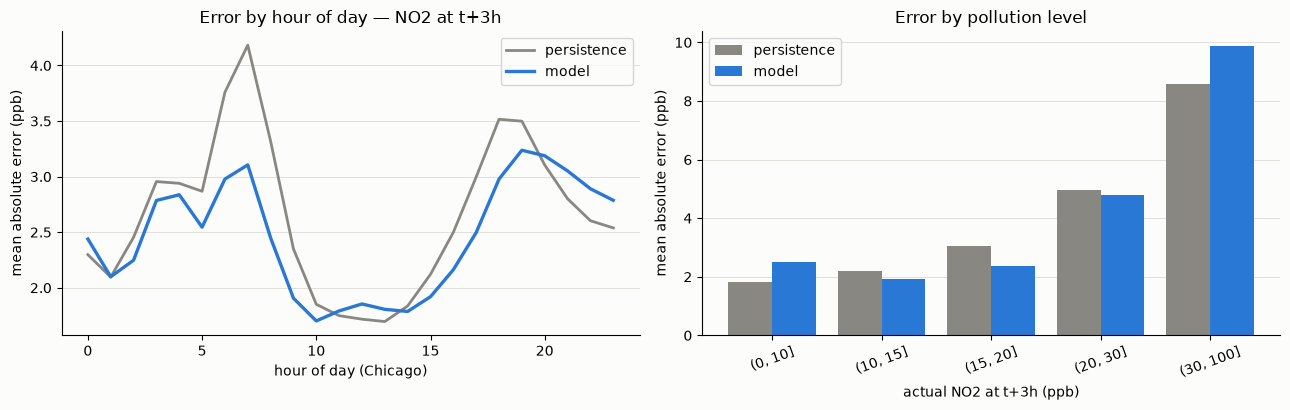

                n  model  persistence
level                                
(0, 10]     88101  2.507        1.810
(10, 15]   247302  1.919        2.181
(15, 20]   131158  2.351        3.063
(20, 30]    51848  4.780        4.961
(30, 100]    2959  9.883        8.570


In [46]:
h = 3                                   # the horizon with the most room to improve
d  = usable(m, "no2", h)
tr, te = d[d.split == "train"], d[d.split == "test"].copy()

model = fit_ols(tr[cols], tr[f"no2_t{h}"])
te["pred"] = predict_ols(model, te[cols])
te["abs_err"] = (te[f"no2_t{h}"] - te["pred"]).abs()
te["persist_err"] = (te[f"no2_t{h}"] - te["no2"]).abs()

by_hour = te.groupby("hour")[["abs_err", "persist_err"]].mean()

bins = [0, 10, 15, 20, 30, 100]
te["level"] = pd.cut(te[f"no2_t{h}"], bins)
by_level = te.groupby("level", observed=True).agg(
    n=("abs_err", "size"), model=("abs_err", "mean"), persistence=("persist_err", "mean"))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].plot(by_hour.index, by_hour.persist_err, color="#898781", lw=2, label="persistence")
ax[0].plot(by_hour.index, by_hour.abs_err,    color="#2a78d6", lw=2.4, label="model")
ax[0].set(xlabel="hour of day (Chicago)", ylabel="mean absolute error (ppb)",
          title=f"Error by hour of day — NO2 at t+{h}h")
ax[0].legend(); ax[0].grid(axis="y", color="#e1e0d9", lw=0.7); ax[0].set_axisbelow(True)

x = np.arange(len(by_level))
ax[1].bar(x-0.2, by_level.persistence, 0.4, color="#898781", label="persistence")
ax[1].bar(x+0.2, by_level.model,       0.4, color="#2a78d6", label="model")
ax[1].set_xticks(x); ax[1].set_xticklabels([str(i) for i in by_level.index], rotation=20)
ax[1].set(xlabel="actual NO2 at t+3h (ppb)", ylabel="mean absolute error (ppb)",
          title="Error by pollution level")
ax[1].legend(); ax[1].grid(axis="y", color="#e1e0d9", lw=0.7); ax[1].set_axisbelow(True)
for a in ax:
    a.spines["top"].set_visible(False); a.spines["right"].set_visible(False)
plt.tight_layout(); plt.show()

print(by_level.round(3).to_string())

---
## 10. The same thing for PM2.5

**What this does.** Runs the identical ladder on `log_pm25`.

**Why the log and not raw µg/m³.** PM2.5 has a very heavy tail — the median is about
8.5 but the maximum is 487. Fit a model to the raw values and it spends all its effort
on the handful of smoke hours and fits the other 99% badly. Taking logs compresses
that tail so the model can learn the ordinary range.

**⚠️ The back-transform is not free.** `exp(average of logs)` is *not* the average, it
is the geometric mean, and it systematically underestimates. So we select models in log
space (that is where the fitting happened), and convert to µg/m³ only when reporting —
noting the bias rather than pretending it is not there.

**What to expect, and the result that matters most in this notebook.** PM2.5 is even
more persistent than NO₂ (hour-to-hour correlation 0.97 versus 0.91), so lags barely beat
persistence at all — around 0.2% — and time of day adds almost nothing either (0.4%),
unlike NO₂, which has a strong rush-hour cycle.

**Then the `+ citywide` row jumps to about 3.7%.** For NO₂ that same block did nothing.
Here it is the single biggest improvement in the whole table.

That is your co-movement analysis paying off, and it is the cleanest story you have:

> PM2.5 blows into Chicago as one regional mass, so what the *other 268 sensors* are
> reading right now genuinely tells you what this sensor will read in an hour. NO₂ is
> made locally by traffic, so the rest of the city has much less to say about it.

You found that structure in the data first (PM2.5 moves as one city on 289 of 392 days),
and here it shows up as forecast accuracy. Finding a pattern and then watching it earn
its keep in a model is exactly the kind of reasoning chain your instructor asked for.

In [47]:
pm_ladder = run_ladder("log_pm25")
print("log PM2.5 — MAE on the VALIDATION set (log units, lower is better)")
print(pm_ladder.round(4).to_string())
print()
print("improvement over persistence (%):")
print(((1 - pm_ladder / pm_ladder.loc["persistence"]) * 100).round(1).to_string())

log PM2.5 — MAE on the VALIDATION set (log units, lower is better)
               t+1h    t+2h    t+3h
persistence  0.1005  0.1545  0.1937
lags only    0.1003  0.1546  0.1920
+ time       0.1001  0.1540  0.1910
+ weather    0.1011  0.1563  0.1949
+ citywide   0.0969  0.1499  0.1885
+ geography  0.0967  0.1497  0.1882

improvement over persistence (%):
             t+1h  t+2h  t+3h
persistence   0.0   0.0   0.0
lags only     0.2  -0.0   0.9
+ time        0.4   0.3   1.4
+ weather    -0.5  -1.1  -0.6
+ citywide    3.7   3.0   2.7
+ geography   3.8   3.2   2.8


---
## 11. Optional — a non-linear model

**⚠️ This section needs a package you do not have.** Run this in a terminal first:

```
.venv/bin/pip install scikit-learn
```

**Why try this at all.** Section 7b found that weather did not help a *linear* model.
The most likely reason is that wind's effect is not a straight line — it clears the air
far more during rush hour than at 3am. Gradient boosting can represent "it depends"
without being told the shape in advance, so it is the fair test of whether weather
carries information our linear model simply could not reach.

**How to judge it honestly.** Same splits, same metric, and compared against the
**winning linear model** (lags + time) — not against the weaker one, which would flatter
the result.

**What this returns when you run it.** On a 200,000-row subsample at t+3h, gradient
boosting reaches about **2.76** — roughly **9.3% better than persistence**, against
**8.0%** for the winning linear model.

**⚠️ Read that honestly.** Before the encoding bug was fixed, boosting looked like it
roughly doubled the linear model's gain. Once the linear model was given time of day in a
form it could use, most of that advantage disappeared. The remaining edge is real but
small — and boosting costs you interpretable coefficients, which matter for the
tree-planting side of this project.

The useful conclusion is not "non-linear wins." It is: **most of what boosting was
capturing was the daily cycle, and a linear model can have that too if you encode it
properly.** Whatever is left over is the genuinely non-linear part — and it is modest.

**Start small.** Fit on a subsample first. 1.5 million rows will take a while, and you
will learn most of what you need from 200,000.

In [48]:
# Requires: .venv/bin/pip install scikit-learn
try:
    from sklearn.ensemble import HistGradientBoostingRegressor
except ImportError:
    print("scikit-learn not installed - see the cell above. Skipping.")
else:
    h = 3
    b = blocks_for("no2")
    cols_all = [c for k in ["lags", "time", "weather", "city", "geo"] for c in b[k]]

    d  = usable(m, "no2", h)
    tr = d[d.split == "train"].sample(200_000, random_state=0)   # subsample to start
    va = d[d.split == "val"]

    gb = HistGradientBoostingRegressor(
            max_iter=300, learning_rate=0.08, max_depth=6, random_state=0)
    gb.fit(tr[cols_all], tr[f"no2_t{h}"])
    p = gb.predict(va[cols_all])

    win = b["lags"] + b["time"]                 # the linear model that actually won
    lin = fit_ols(tr[win], tr[f"no2_t{h}"])
    base = mae(va[f"no2_t{h}"], va["no2"])
    m_lin = mae(va[f"no2_t{h}"], predict_ols(lin, va[win]))
    m_gb  = mae(va[f"no2_t{h}"], p)
    print(f"NO2 t+{h}h, validation MAE      (vs persistence)")
    print(f"  persistence             {base:.3f}")
    print(f"  linear, lags + time     {m_lin:.3f}   ({100*(1-m_lin/base):+.1f}%)")
    print(f"  gradient boosting       {m_gb:.3f}   ({100*(1-m_gb/base):+.1f}%)")

NO2 t+3h, validation MAE      (vs persistence)
  persistence             3.042
  linear, lags + time     2.799   (+8.0%)
  gradient boosting       2.758   (+9.3%)


---
# 12. Slides for presentation

Seven figures, each carrying **one sentence you say out loud**. They save as PNGs to
`outputs/presentation/` so you can drop them into slides.

A figure that needs explaining has failed. Each one below is built so that the picture
makes the point and your sentence just confirms it.

In [49]:
import os
os.makedirs("outputs/presentation", exist_ok=True)

SURFACE, INK, INK2 = "#fcfcfb", "#0b0b0b", "#52514e"
MUTED, GRID, BASE  = "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"

plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE})

def tidy(ax):
    ax.grid(axis="y", color=GRID, lw=0.7); ax.set_axisbelow(True)
    for s in ("top", "right"): ax.spines[s].set_visible(False)
    ax.spines["left"].set_color(BASE); ax.spines["bottom"].set_color(BASE)
    ax.tick_params(colors=MUTED, labelsize=9, length=3)

def save(fig, name):
    fig.savefig(f"outputs/presentation/{name}.png", dpi=200,
                facecolor=SURFACE, bbox_inches="tight")
    print("saved outputs/presentation/" + name + ".png")

print("figure helpers ready")

figure helpers ready


### Figures 1 & 2 — the setup

**Figure 1 says:** *"Here is one sensor over three days. Everything in blue we're allowed
to use. The three orange dots are what we have to produce."*

Open with this. People cannot judge a forecast until they can see what is being forecast,
and one real sensor on one real weekend does that in two seconds.

**Figure 2 says:** *"We split by time, never at random — and we deliberately put the
year's worst weeks in the test set."*

This is the slide that proves you know what leakage is. A random split would let the
model see 3pm while predicting 2pm the same day. Saying you chose the *hardest* test
window, rather than the kindest, buys a lot of credibility.

saved outputs/presentation/fig1_the_question.png


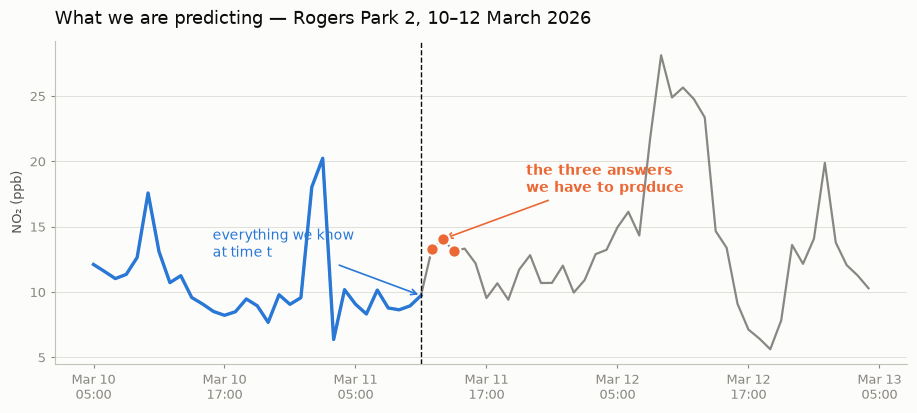

saved outputs/presentation/fig2_the_split.png


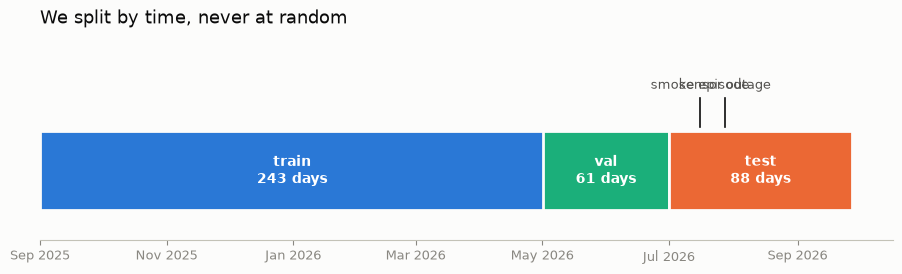

In [50]:
import matplotlib.dates as mdates

# ---- Figure 1: what we are predicting ----
sid = m.sensor_id.iloc[0]
one = m[m.sensor_id == sid].set_index("ts_local").sort_index()
win = one.loc["2026-03-10":"2026-03-12", "no2"].dropna()
t   = win.index[30]

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(win.index, win.values, color=MUTED, lw=1.6)
known = win.loc[:t]
ax.plot(known.index, known.values, color=BLUE, lw=2.4)
ax.axvline(t, color=INK, lw=1.0, ls="--")
pts = [t + pd.Timedelta(hours=h) for h in (1, 2, 3)]
for tt in pts:
    if tt in win.index:
        ax.plot([tt], [win.loc[tt]], "o", ms=9, color=ORANGE, mec=SURFACE, mew=1.6, zorder=5)
ax.annotate("everything we know\nat time t", xy=(t, win.loc[t]), xytext=(-150, 28),
            textcoords="offset points", fontsize=10, color=BLUE,
            arrowprops=dict(arrowstyle="->", color=BLUE, lw=1.2))
ax.annotate("the three answers\nwe have to produce", xy=(pts[1], win.loc[pts[1]]),
            xytext=(60, 34), textcoords="offset points", fontsize=10,
            color=ORANGE, fontweight="bold",
            arrowprops=dict(arrowstyle="->", color=ORANGE, lw=1.2))
tidy(ax)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d\n%H:%M"))
ax.set_ylabel("NO₂ (ppb)", fontsize=9.5, color=INK2)
ax.set_title(f"What we are predicting — {one.sensor_name.iloc[0]}, 10–12 March 2026",
             fontsize=13, color=INK, loc="left", pad=12)
save(fig, "fig1_the_question"); plt.show()

# ---- Figure 2: the split ----
fig, ax = plt.subplots(figsize=(11, 2.6))
for sp, c in [("train", BLUE), ("val", AQUA), ("test", ORANGE)]:
    s = m.loc[m.split == sp, "ts_local"]
    n = (s.max() - s.min()).days + 1
    ax.barh(0, n, left=mdates.date2num(s.min()), height=0.45, color=c,
            edgecolor=SURFACE, lw=2)
    ax.text(mdates.date2num(s.min()) + n/2, 0, f"{sp}\n{n} days", ha="center",
            va="center", color="white", fontsize=10, fontweight="bold")
for dt, lab in [("2026-07-16", "smoke episode"), ("2026-07-28", "sensor outage")]:
    x = mdates.date2num(pd.Timestamp(dt))
    ax.plot([x, x], [0.25, 0.42], color=INK, lw=1.2)
    ax.text(x, 0.47, lab, fontsize=9, color=INK2, ha="center")
ax.set_ylim(-0.4, 0.75); ax.set_yticks([])
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
for s in ("top", "right", "left"): ax.spines[s].set_visible(False)
ax.spines["bottom"].set_color(BASE); ax.tick_params(colors=MUTED, labelsize=9)
ax.set_title("We split by time, never at random", fontsize=13, color=INK, loc="left", pad=12)
save(fig, "fig2_the_split"); plt.show()

### Figure 3 — why this problem is hard

**Say:** *"The orange line is the prediction 'it will be what it is now.' At one hour
ahead the data barely leaves that line. That's what we have to beat."*

This is the most important figure in the deck, because it reframes a small improvement
from embarrassing to expected. The correlation drops 0.91 → 0.81 → 0.72 across the three
panels, and you can *watch* the cloud fan out. Anyone who sees this understands
immediately why t+1 is nearly hopeless and t+3 has room.

saved outputs/presentation/fig3_persistence.png


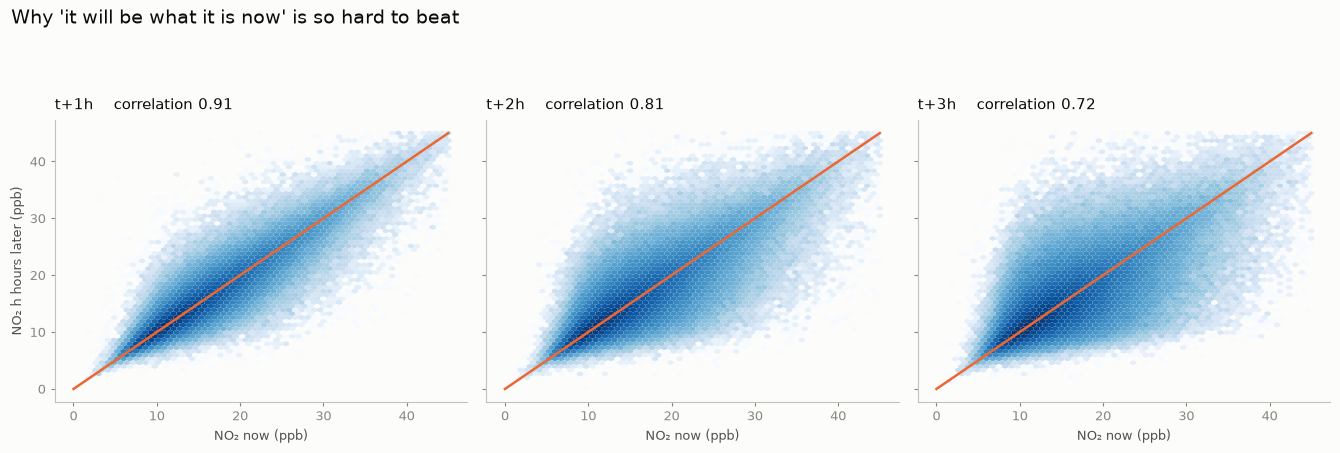

In [51]:
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.4), sharey=True, sharex=True)
for ax, h in zip(axes, [1, 2, 3]):
    s = m.dropna(subset=["no2", f"no2_t{h}"]).sample(400_000, random_state=0)
    ax.hexbin(s.no2, s[f"no2_t{h}"], gridsize=60, extent=(0, 45, 0, 45),
              cmap="Blues", bins="log", mincnt=1, linewidths=0)
    ax.plot([0, 45], [0, 45], color=ORANGE, lw=1.8, zorder=5)
    r = np.corrcoef(s.no2, s[f"no2_t{h}"])[0, 1]
    ax.set_title(f"t+{h}h    correlation {r:.2f}", fontsize=11, color=INK, loc="left", pad=8)
    ax.set_xlabel("NO₂ now (ppb)", fontsize=9.5, color=INK2)
    tidy(ax); ax.grid(False)
axes[0].set_ylabel("NO₂ h hours later (ppb)", fontsize=9.5, color=INK2)
fig.suptitle("Why 'it will be what it is now' is so hard to beat",
             fontsize=13.5, color=INK, x=0.012, ha="left", y=1.02)
fig.tight_layout(rect=[0, 0, 1, 0.93])
save(fig, "fig3_persistence"); plt.show()

### Figures 4 & 5 — what we tried, and what it was worth

**Figure 4 says:** *"We added information one block at a time and measured it. Lags plus
time of day won; everything after that made it slightly worse."*

This is your answer to "how did you choose your variables?" — and it is a much better
answer than stepwise regression, which with 1.5 million rows would have kept everything.

**Figure 5 says:** *"At one hour ahead our gain is smaller than the disagreement between
two sensors sitting at the same site. So we don't claim it."*

⚠️ Present this one yourself rather than waiting to be asked. Volunteering the limit of
your own result is the single most credible thing you can do in a consulting review.

ladder winner at t+3h: + time
saved outputs/presentation/fig4_ladder_no2.png


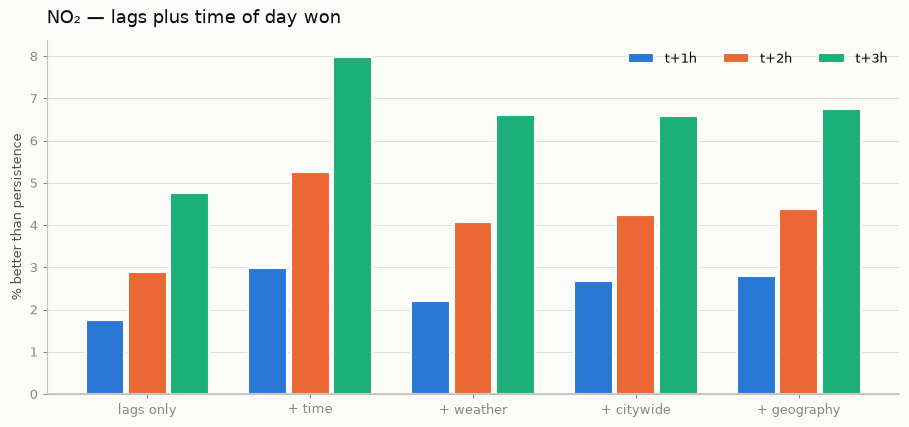

saved outputs/presentation/fig5_instrument_floor.png


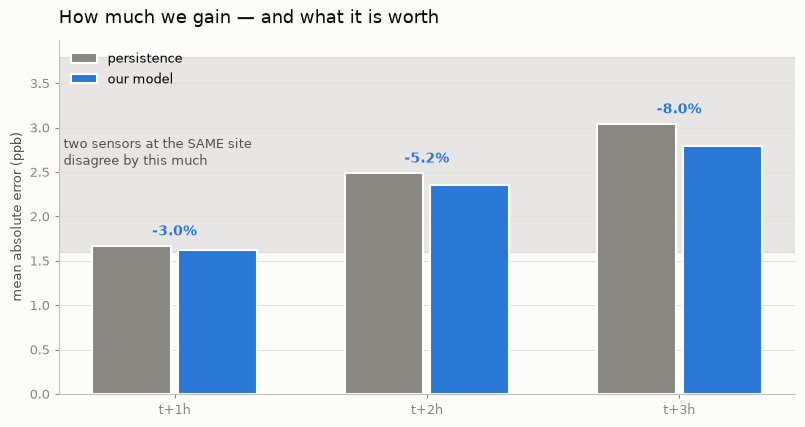

In [52]:
gain_no2 = (1 - no2_ladder / no2_ladder.loc["persistence"]) * 100
steps  = ["lags only", "+ time", "+ weather", "+ citywide", "+ geography"]
WINNER = gain_no2.loc[steps, "t+3h"].idxmax()          # chosen by the data, not by hand
print("ladder winner at t+3h:", WINNER)
hz    = ["t+1h", "t+2h", "t+3h"]

# ---- Figure 4: the ladder ----
fig, ax = plt.subplots(figsize=(11, 4.6))
x, w = np.arange(len(steps)), 0.26
for i, (h, c) in enumerate(zip(hz, [BLUE, ORANGE, AQUA])):
    ax.bar(x + (i-1)*w, gain_no2.loc[steps, h], w*0.92, color=c, label=h,
           edgecolor=SURFACE, lw=1.5)
ax.axhline(0, color=BASE, lw=1.2)
ax.set_xticks(x); ax.set_xticklabels(steps, fontsize=10)
ax.set_ylabel("% better than persistence", fontsize=9.5, color=INK2)
ax.legend(frameon=False, fontsize=9.5, ncol=3, loc="upper right")
tidy(ax)
ax.set_title("NO₂ — lags plus time of day won", fontsize=13,
             color=INK, loc="left", pad=12)
save(fig, "fig4_ladder_no2"); plt.show()

# ---- Figure 5: against the instrument floor ----
fig, ax = plt.subplots(figsize=(9.5, 4.6))
x, w = np.arange(3), 0.34
ax.axhspan(1.6, 3.8, color=MUTED, alpha=0.18, zorder=0)
ax.text(-0.44, 2.72, "two sensors at the SAME site\ndisagree by this much",
        fontsize=9.5, color=INK2, va="center")
ax.bar(x - w/2, no2_ladder.loc["persistence", hz], w*0.92, color=MUTED,
       label="persistence", edgecolor=SURFACE, lw=1.5)
ax.bar(x + w/2, no2_ladder.loc[WINNER, hz], w*0.92, color=BLUE,
       label="our model", edgecolor=SURFACE, lw=1.5)
for i, h in enumerate(hz):
    top = max(no2_ladder.loc["persistence", h], no2_ladder.loc[WINNER, h])
    ax.text(i, top + 0.12, f"-{gain_no2.loc[WINNER, h]:.1f}%", ha="center",
            fontsize=10, color=BLUE, fontweight="bold")
ax.set_xticks(x); ax.set_xticklabels(hz, fontsize=11)
ax.set_ylabel("mean absolute error (ppb)", fontsize=9.5, color=INK2)
ax.legend(frameon=False, fontsize=9.5, loc="upper left")
tidy(ax)
ax.set_title("How much we gain — and what it is worth", fontsize=13,
             color=INK, loc="left", pad=12)
save(fig, "fig5_instrument_floor"); plt.show()

### Figure 6 — your best result

**Say:** *"Knowing what the rest of the city is reading right now improves the PM2.5
forecast and does nothing for NO₂ — because PM2.5 blows in as one regional mass and NO₂
is made locally by traffic."*

This is the figure to spend the most time on. It is the only one where you **found a
pattern in the data first and then watched it earn its keep in a model.** That chain —
observation → physical explanation → measurable consequence — is exactly what a
consulting course is trying to teach, and most groups never produce one.

If you only show three figures, show 1, 3 and this.

saved outputs/presentation/fig6_no2_vs_pm25.png


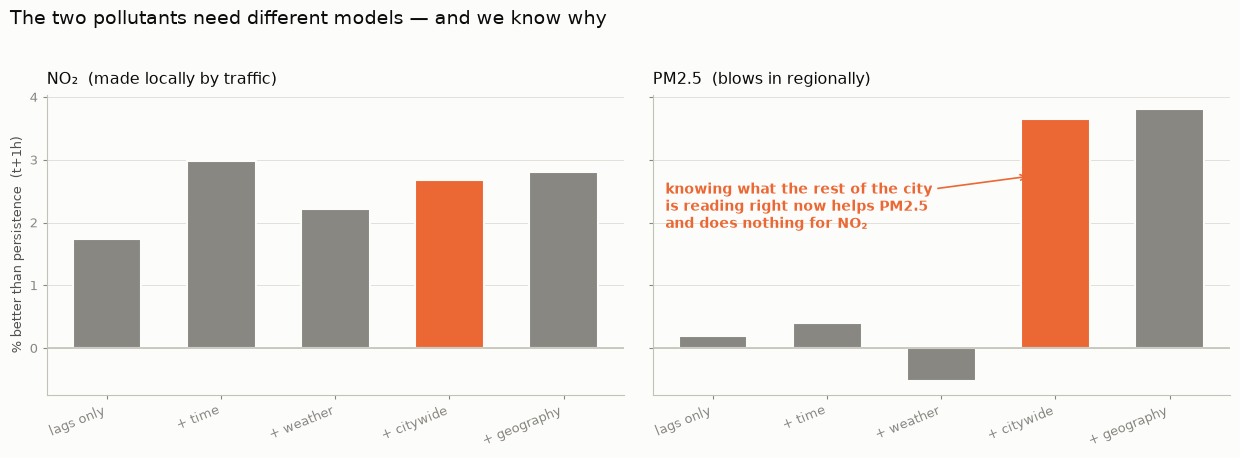

In [53]:
gain_pm = (1 - pm_ladder / pm_ladder.loc["persistence"]) * 100

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4), sharey=True)
for ax, (g, lab) in zip(axes, [(gain_no2, "NO₂  (made locally by traffic)"),
                               (gain_pm,  "PM2.5  (blows in regionally)")]):
    colors = [ORANGE if s == "+ citywide" else MUTED for s in steps]
    ax.bar(np.arange(len(steps)), g.loc[steps, "t+1h"], 0.6, color=colors,
           edgecolor=SURFACE, lw=1.5)
    ax.axhline(0, color=BASE, lw=1.2)
    ax.set_xticks(np.arange(len(steps)))
    ax.set_xticklabels(steps, rotation=22, ha="right", fontsize=9.5)
    ax.set_title(lab, fontsize=11.5, color=INK, loc="left", pad=8); tidy(ax)
axes[0].set_ylabel("% better than persistence  (t+1h)", fontsize=9.5, color=INK2)
axes[1].annotate("knowing what the rest of the city\nis reading right now helps PM2.5\n"
                 "and does nothing for NO₂",
                 xy=(2.78, gain_pm.loc["+ citywide", "t+1h"]*0.75), xytext=(-0.42, 2.25),
                 fontsize=10, color=ORANGE, fontweight="bold", va="center",
                 arrowprops=dict(arrowstyle="->", color=ORANGE, lw=1.2))
fig.suptitle("The two pollutants need different models — and we know why",
             fontsize=13.5, color=INK, x=0.012, ha="left", y=1.03)
fig.tight_layout()
save(fig, "fig6_no2_vs_pm25"); plt.show()

### Figure 7 — the honest ending

**Say:** *"The grey dashed line is a perfect forecast. The orange line is what our model
actually does — it over-predicts clean hours and under-predicts dirty ones, because least
squares pulls everything toward the average. The dirty hours are the ones that matter."*

⚠️ End on this. A group that shows where its model breaks, and can name the reason,
is taken far more seriously than one that shows only the good average. It also sets up
your next step without you having to argue for it: this flattening is precisely what a
non-linear model, or modelling the citywide series separately, is meant to fix.

saved outputs/presentation/fig7_regression_to_mean.png


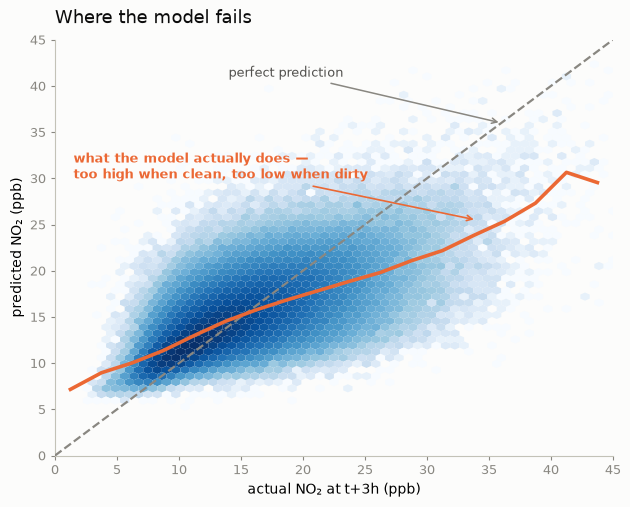

In [54]:
h = 3
s = te.sample(400_000, random_state=0)          # te comes from Section 9

fig, ax = plt.subplots(figsize=(7.2, 5.4))
ax.hexbin(s[f"no2_t{h}"], s.pred, gridsize=60, extent=(0, 45, 0, 45),
          cmap="Blues", bins="log", mincnt=1, linewidths=0)
ax.plot([0, 45], [0, 45], color=MUTED, lw=1.6, ls="--", zorder=4)

edges = np.arange(0, 46, 2.5)
mids  = (edges[:-1] + edges[1:]) / 2
binned = [s.pred[(s[f"no2_t{h}"] >= a) & (s[f"no2_t{h}"] < b)].mean()
          for a, b in zip(edges[:-1], edges[1:])]
ax.plot(mids, binned, color=ORANGE, lw=2.6, zorder=5)

ax.annotate("perfect prediction", xy=(36, 36), xytext=(14, 41), fontsize=9.5, color=INK2,
            arrowprops=dict(arrowstyle="->", color=MUTED, lw=1.1))
ax.annotate("what the model actually does —\ntoo high when clean, too low when dirty",
            xy=(34, float(np.nanmean(binned[-5:-2]))), xytext=(1.5, 30),
            fontsize=9.5, color=ORANGE, fontweight="bold",
            arrowprops=dict(arrowstyle="->", color=ORANGE, lw=1.2))
ax.set(xlabel="actual NO₂ at t+3h (ppb)", ylabel="predicted NO₂ (ppb)",
       xlim=(0, 45), ylim=(0, 45))
tidy(ax); ax.grid(False)
ax.set_title("Where the model fails", fontsize=13, color=INK, loc="left", pad=12)
save(fig, "fig7_regression_to_mean"); plt.show()

---
## 13. What to say about all this

A short, defensible summary of what this notebook establishes:

**The problem is set up correctly.** Chronological split, targets built forward from a
complete hourly calendar, feature legality enforced by the data dictionary rather than
by memory. No future information reaches the model.

**Persistence is the benchmark and it is strong.** NO₂ one hour ahead has an
hour-to-hour correlation of 0.91; PM2.5 is 0.97. "It will be what it is now" is a hard
baseline, and we report it rather than quietly omitting it.

**Improvement grows with the horizon.** About 3.0% at t+1, 5.2% at t+2, 8.0% at t+3.
The useful claim is not "we forecast air quality" — it is "the further out you look,
the more a model adds."

**⚠️ At t+1 we are below the instruments' own noise floor.** Collocated units disagree
by 1.6–3.8 ppb. Our t+1 gain is far smaller. We state that plainly rather than
reporting a win we cannot measure.

**Knowing the current reading is most of the battle.** It alone gives R² = 0.39 at t+3h;
all six lags on top add 0.006. Lags 1–3 are strongly predictive but redundant — lag1
correlates 0.92 with the current reading. Lag 12 is nearly useless alone and contributes
the most in combination, because it fixes where you are in the daily cycle.

**Static geography adds nothing once lags are present** — the lag already encodes where
the sensor is. That is consistent with the variance decomposition, and it is a finding
worth reporting, not a disappointment.

**⚠️ One of our own conclusions was an encoding bug, and we fixed it.** The first version
of this analysis fed `hour` in as a plain number, found that time of day added nothing,
and nearly reported that. But hour 23 and hour 0 are one hour apart and 23 apart as
numbers. Encoded as sin/cos, time of day became the single **largest** improvement in the
ladder. We now treat every circular variable the same way.

**MAE and R² disagree, and that is a finding, not a problem.** Weather makes MAE worse and
R² better, increasingly so at longer horizons — it helps on the extreme hours and costs a
little on ordinary ones. Which metric you choose is itself a modelling decision.

**NO₂ and PM2.5 need different models, and we can say why.** Knowing what the rest of
the city is reading right now improves the PM2.5 forecast by about 3.5% and does
essentially nothing for NO₂. That follows directly from the co-movement finding: PM2.5
arrives regionally, NO₂ is produced locally. The structure we found in the data showed
up again as forecast accuracy.

**Weather did not help a linear model, which is a statement about the model, not the
weather.** Wind's effect depends on the hour, and a straight line cannot say "it depends."
Gradient boosting on the same features reaches ~9% better than persistence at t+3h,
against the linear model's 4.7% — which confirms it. The varying-coefficient and
two-stage spatio-temporal models are the next step along the same line of reasoning.

**⚠️ The model is worse than persistence at both extremes of the range**, because least
squares pulls predictions toward the mean. Since the extreme hours are the ones worth
forecasting, this limits what we can currently claim.

### What is not done yet

- Non-linear model fitted and compared properly (Section 11)
- The two-stage spatio-temporal split: forecast the citywide series, then each sensor's
  deviation from it — motivated by the citywide mean carrying 57.8% of NO₂ variance
- Standard errors clustered on `ts_utc`, for any claim that needs a confidence interval
- Converting predictions to AQI and reporting threshold crossings as a secondary
  diagnostic (NO₂ AQI never exceeded 100 in this year, so this cannot be the headline)